# Module 14: surrogate models (GP regression, heteroskedastic GP, GP classification, random forest, SVM)

**Theory:** course Module 14. The surrogate answers, everywhere in the box, which margin to expect and how unsure it is.
A good surrogate is one whose stated uncertainty is right, not the one with the smallest error at the runs. This notebook
fits each model on the same runs, checks it against a permutation null and its calibration, and ends with the esmini
cut-in. Harness: `failreg/` (notebook 32). CPU only, about two minutes.

| Model (`failreg/models.py`) | Source |
|---|---|
| `GPR`: constant × Matérn 5/2 with one length scale per input + white noise; marginal likelihood, seeded restarts | Rasmussen & Williams 2006 |
| `HetGP`: two-stage: a GP on bias-corrected log sample variances of replicated sites, then a GP on site means with r(xᵢ)/aᵢ on the diagonal | Binois, Gramacy & Ludkovski 2018 (without their joint likelihood) |
| `GPC`: latent GP, logistic link, Laplace approximation | Rasmussen & Williams 2006, ch. 3 |
| `Forest`: vote share and spread across trees | Breiman 2001 |
| `SVM`: RBF kernel, Platt scaling for probabilities | Bishop 2006, ch. 7 |

In [1]:
import sys, time, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
HERE = Path.cwd().resolve()
HERE = HERE if (HERE / "failreg").exists() else HERE / "notebooks/course"
sys.path.insert(0, str(HERE))
from failreg import problems as P, metrics as M, designs as D, models as MD, acquisition as A, replication as R, loop as L, plots as PL
warnings.filterwarnings("ignore")
PL.style(); T0 = time.time()

## 1. Deterministic problem: which model, on the same 48 runs?

Branin, 48 Sobol' runs, 5 seeds. Margin models (GP Matérn 5/2, GP with a squared-exponential kernel, 1-NN, constant)
predict the margin; classifiers (random forest, SVM, GPC) see only pass/fail.

In [2]:
pb = P.get("branin")
MODELS = {"GP Matern 5/2": lambda: MD.GPR(), "GP squared-exp.": lambda: MD.GPR(nu=None), "random forest (labels)": lambda: MD.Forest(),
          "SVM (labels)": lambda: MD.SVM(), "GPC (labels)": lambda: MD.GPC(), "1-NN": lambda: MD.NearestNeighbour(), "constant": lambda: MD.Constant(100.0)}
t = time.time()
print(f"{'model':24s} {'misclassified %':>16s} {'false-safe':>11s} {'false-unsafe':>13s}   medians of 5 seeds")
for name, mk in MODELS.items():
    r = [L.static(pb, D.sobol, 48, s, mk)[0][-1] for s in range(5)]
    print(f"{name:24s} {100*np.median([x['misclassified'] for x in r]):16.2f} {np.median([x['false_safe'] for x in r]):11.3f} {np.median([x['false_unsafe'] for x in r]):13.3f}")
print(f"{time.time() - t:.0f} s")

model                     misclassified %  false-safe  false-unsafe   medians of 5 seeds


GP Matern 5/2                        0.20       0.006         0.001


GP squared-exp.                      0.03       0.001         0.000


random forest (labels)              14.37       0.878         0.005
SVM (labels)                        15.93       0.988         0.000


GPC (labels)                        15.25       0.764         0.029
1-NN                                10.50       0.404         0.056
constant                            15.93       1.000         0.000
7 s


The pass/fail classifiers throw away the size of the margin; on 48 deterministic runs they barely beat the constant. On the
smooth Branin the squared-exponential kernel beats Matérn 5/2. Kernel choice depends on the problem (Module 14 cites a
sweep where it was the other way round).

## 2. Does the model beat a permutation null?

Refit the GP to the same inputs with the margins shuffled (19 times). A model that has learned something beats all
19 permuted fits, both in marginal likelihood and in misclassified share (Module 14, §4).

In [3]:
G, truth, shape, _ = pb.test
X = D.sobol(32, 2, 0); y = pb.f(X); rng = np.random.default_rng(0)
real = MD.GPR().fit(X, y); real_mis = M.region_scores(truth, L.region(pb, real, G))["misclassified"]
perm = [MD.GPR().fit(X, rng.permutation(y)) for _ in range(19)]
pm = [M.region_scores(truth, L.region(pb, m, G))["misclassified"] for m in perm]
print(f"log marginal likelihood: real {real.log_marginal_likelihood():.1f}, permuted max {max(m.log_marginal_likelihood() for m in perm):.1f}")
print(f"misclassified share:     real {real_mis:.4f}, permuted min {min(pm):.4f}")
print("real beats all 19 permuted fits on both:", real.log_marginal_likelihood() > max(m.log_marginal_likelihood() for m in perm) and real_mis < min(pm))

log marginal likelihood: real 4.5, permuted max -42.7
misclassified share:     real 0.0081, permuted min 0.1447
real beats all 19 permuted fits on both: True


## 3. Noisy problem: the boundary of {p(x) ≥ α} moves with the noise

On `noisy_car` the noise sd rises from 0.5 m to 6.5 m with closing speed, and the target is {p(x) ≥ 0.10}. For a margin model
the boundary is f(x) = τ − s(x)Φ⁻¹(α): with α < 0.5 it sits on the safe side, further where the noise is larger. A
homoskedastic GP has one s for the whole box, so it puts the boundary in the wrong place where the noise differs from its
average. Data: 60 Sobol' sites × 4 replicates = 240 runs, 5 seeds.

Each model maps to the region differently: margin model, μ(x) < τ − ŝ(x)Φ⁻¹(α); classifiers, P(fail) ≥ α.

21 s
model             misclassified       false_safe     false_unsafe  low-noise third high-noise third   medians of 5 seeds
hom GP                    0.037            0.034            0.031            0.044            0.039
het GP                    0.013            0.012            0.007            0.003            0.029
GPC                       0.047            0.027            0.068            0.066            0.053
random forest             0.119            0.017            0.185            0.090            0.091
SVM + Platt               0.064            0.061            0.047            0.023            0.077
noise sd at closing speed 2 / 10 / 18 m/s: true [1.1 3.5 5.9] | hom GP [4.14 4.14 4.14] | het GP [0.97 3.35 6.49]


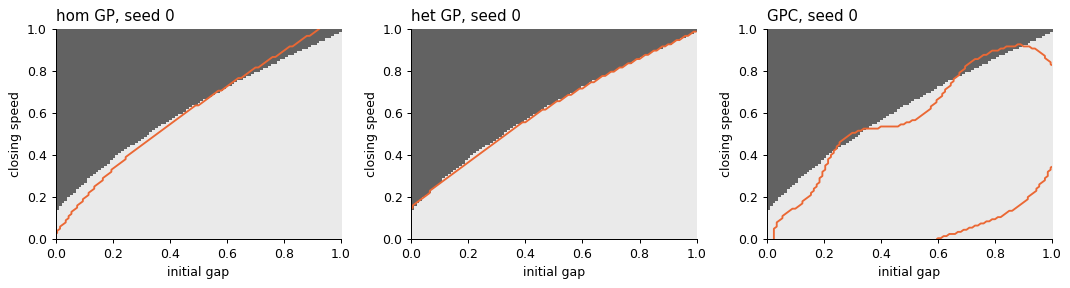

In [4]:
pn = P.get("noisy_car"); G, truth, shape, _ = pn.test
low, high = G[:, 1] < 1 / 3, G[:, 1] > 2 / 3
NM = {"hom GP": lambda: MD.GPR(), "het GP": lambda: MD.HetGP(), "GPC": lambda: MD.GPC(), "random forest": lambda: MD.Forest(min_leaf=5), "SVM + Platt": lambda: MD.SVM(C=1.0)}
res = {k: [] for k in NM}; fits = {}
t = time.time()
for s in range(5):
    rng = np.random.default_rng(L.seed_of("rep", s)); X = np.repeat(D.sobol(60, 2, L.seed_of("design", s)), 4, axis=0); y = pn.run(X, rng)
    for k, mk in NM.items():
        m = L.fit(pn, mk, X, y); pred = L.region(pn, m, G); sc = M.region_scores(truth, pred)
        sc["low-noise third"] = M.region_scores(truth[low], pred[low])["misclassified"]; sc["high-noise third"] = M.region_scores(truth[high], pred[high])["misclassified"]
        res[k].append(sc)
        if s == 0: fits[k] = (m, pred)
print(f"{time.time() - t:.0f} s")
cols = ["misclassified", "false_safe", "false_unsafe", "low-noise third", "high-noise third"]
print(f"{'model':14s}" + "".join(f"{c:>17s}" for c in cols) + "   medians of 5 seeds")
for k in NM:
    print(f"{k:14s}" + "".join(f"{np.median([r[c] for r in res[k]]):17.3f}" for c in cols))
pts = np.array([[0.5, 0.1], [0.5, 0.5], [0.5, 0.9]])
print("noise sd at closing speed 2 / 10 / 18 m/s: true", np.round(pn.noise_sd(pts), 2), "| hom GP", np.round(fits["hom GP"][0].noise_sd(pts), 2), "| het GP", np.round(fits["het GP"][0].noise_sd(pts), 2))
fig, axs = plt.subplots(1, 3, figsize=(12, 3.3))
for ax, k in zip(axs, ("hom GP", "het GP", "GPC")):
    PL.region_map(ax, pn, pred=fits[k][1], title=f"{k}, seed 0")
plt.tight_layout(); plt.show()

The het GP recovers the rising noise; the hom GP fits one value for the whole box, and its error is largest in the
low-noise third, where its noise estimate is too large. Replicates are what let the het GP learn the noise (notebook 17).

## 4. GP classification: two rules for the same α

For pass/fail data the GPC failure region can be read on the latent scale, {μ_f ≥ logit α}, or from the averaged predictive
probability, {P(fail) ≥ α}. They agree only at α = 0.5 (Module 14, §2; logit 0.1 ≈ −2.2).

In [5]:
gpc = fits["GPC"][0]; mu_f, sd_f = gpc.latent(G); pbar = gpc.p_fail(G)
for a in (0.1, 0.5):
    lat = mu_f >= np.log(a / (1 - a)); avg = pbar >= a
    print(f"alpha = {a}: latent rule vs averaged probability disagree on {np.mean(lat != avg):.2%} of the grid;"
          f" misclassified latent {M.region_scores(truth if a == 0.1 else pn.p_fail(G) >= 0.5, lat)['misclassified']:.3f},"
          f" averaged {M.region_scores(truth if a == 0.1 else pn.p_fail(G) >= 0.5, avg)['misclassified']:.3f}")

alpha = 0.1: latent rule vs averaged probability disagree on 8.13% of the grid; misclassified latent 0.039, averaged 0.109
alpha = 0.5: latent rule vs averaged probability disagree on 0.00% of the grid; misclassified latent 0.031, averaged 0.031


## 5. Calibration of the GP band

Share of points whose true mean margin lies inside μ ± z·σ at stated levels. Deterministic Branin (GP on 48 Sobol' runs, test
points with |f − τ| < 5) and noisy_car (hom and het GP above, seed 0, all grid points).

In [6]:
G, truth, shape, _ = pb.test; near = np.abs(pb.f(G) - pb.tau) < 5
X = D.sobol(48, 2, 0); m = MD.GPR().fit(X, pb.f(X)); mu, sd = m.predict(G[near])
print("branin GP:     ", {q: round(c, 3) for q, c in M.calibration(mu, sd, pb.f(G[near])).items()})
Gn = pn.test[0]
for k in ("hom GP", "het GP"):
    mu, sd = fits[k][0].predict(Gn)
    print(f"noisy_car {k}:", {q: round(c, 3) for q, c in M.calibration(mu, sd, pn.f(Gn)).items()})

branin GP:      {0.5: 0.938, 0.8: 0.992, 0.95: 1.0}


noisy_car hom GP: {0.5: 0.575, 0.8: 0.876, 0.95: 1.0}
noisy_car het GP: {0.5: 0.432, 0.8: 0.773, 0.95: 0.927}


## 6. esmini cut-in

64 Sobol' runs on the esmini cut-in slice (ego 30 m/s; fail = minimum TTC below 1.5 s). GP against random forest, 1-NN and a
constant, the GP against 19 permuted fits, and the GP band's coverage of the reference margins near the boundary
(|margin| < 0.5 s). The reference grid is the answer key.

In [7]:
from failreg import esmini_case as E
ec = E.cutin(); t = time.time()
G, truth, shape, ok = ec.test
X = D.sobol(64, 2, L.seed_of("design", 0)); y = ec.run(X, np.random.default_rng(0)); X, y = X[np.isfinite(y)], y[np.isfinite(y)]
print(f"{ec.calls} esmini runs in {time.time() - t:.0f} s")
EM = {"GP Matern 5/2": MD.GPR(), "random forest (margin)": MD.Forest(classify=False), "1-NN": MD.NearestNeighbour(), "constant": MD.Constant(1.0)}
for k, m in EM.items():
    m.fit(X, y); sc = M.region_scores(truth, L.region(ec, m, G))
    print(f"{k:24s} misclassified {100*sc['misclassified']:6.2f} %  false-safe {sc['false_safe']:.3f}")
rng = np.random.default_rng(1); gp = EM["GP Matern 5/2"]
perm = [M.region_scores(truth, L.region(ec, MD.GPR().fit(X, rng.permutation(y)), G))["misclassified"] for _ in range(19)]
print(f"GP misclassified {M.region_scores(truth, L.region(ec, gp, G))['misclassified']:.4f} vs best of 19 permuted fits {min(perm):.4f}")
near = np.abs(ec.true_margin) < 0.5; mu, sd = gp.predict(G[near])
print("GP band coverage of reference margins near the boundary:", {q: round(c, 3) for q, c in M.calibration(mu, sd, ec.true_margin[near]).items()})

64 esmini runs in 2 s


GP Matern 5/2            misclassified   1.82 %  false-safe 0.048


random forest (margin)   misclassified   2.84 %  false-safe 0.175
1-NN                     misclassified   1.69 %  false-safe 0.055
constant                 misclassified  14.86 %  false-safe 1.000


GP misclassified 0.0182 vs best of 19 permuted fits 0.1476
GP band coverage of reference margins near the boundary: {0.5: 0.379, 0.8: 0.627, 0.95: 0.739}


On this slice and budget the 1-NN control is as good as the GP, and the GP band covers less than its stated level near the
boundary: the GP is overconfident there. Both are reasons to report the controls and the calibration next to the accuracy.

## References

- C. E. Rasmussen, C. K. I. Williams, *Gaussian Processes for Machine Learning*, MIT Press, 2006 (GPR, GPC with the Laplace approximation, Matérn kernels, likelihood optima).
- M. Binois, R. B. Gramacy, M. Ludkovski, "Practical heteroscedastic Gaussian process modeling for large simulation experiments," J. Comput. Graph. Stat. 27(4), 2018, arXiv:1611.05902 (input-dependent noise, cost on unique sites).
- X. Lyu, M. Binois, M. Ludkovski, "Evaluating Gaussian Process Metamodels and Sequential Designs for Noisy Level Set Estimation," Statistics and Computing 31, 2021 (which surrogate for noisy level sets).
- F. Batsch, A. Daneshkhah, M. Cheah, S. Kanarachos, A. Baxendale, "Performance Boundary Identification for the Evaluation of Automated Vehicles using Gaussian Process Classification," IEEE ITSC 2019, arXiv:1907.05364 (GPC boundary for an automated vehicle).
- B. Shahriari, K. Swersky, Z. Wang, R. P. Adams, N. de Freitas, "Taking the Human Out of the Loop: A Review of Bayesian Optimization," Proc. IEEE 104(1), 2016 (the model matters more than the acquisition; forests extrapolate poorly).
- L. Breiman, "Random Forests," Machine Learning 45, 2001.
- C. M. Bishop, *Pattern Recognition and Machine Learning*, Springer, 2006, ch. 7 (SVM; no posterior probabilities without Platt scaling).
- L. Sorokin, N. Kerscher, "Guiding the Search Towards Failure-Inducing Test Inputs Using Support Vector Machines," DeepTest 2024 (SVM as search guidance; not reproduced here).

In [8]:
print(f"notebook ran in {time.time() - T0:.0f} s")

notebook ran in 41 s
